##Install packages

In [2]:
!pip -q install unsloth matplotlib pandas scikit-learn nltk


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.4/82.4 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.4/28.4 MB 78.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 112.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 107.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 121.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 120.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.9/216.9 kB 23.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 121.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 25.8 MB/s eta 0:00:00


## Mount Google Drive

In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


##Paths and settings

In [4]:
from pathlib import Path
import os, json, math, random, shutil
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

SEED = 3407
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DAPT_MODEL_ID = "ksumanthreddy96/studymate-ctp-dapt"
ZIP_PATH = Path("/content/studymate_ctp_sft_dataset.zip")
DATA_DIR = Path("/content/studymate_sft_data")
TRAIN_PATH = DATA_DIR / "sft_train.jsonl"
TEST_PATH = DATA_DIR / "sft_test.jsonl"

DAPT_BACKUP_DIR = Path("/content/drive/MyDrive/ctp/studymate-dapt-backup")
SFT_OUTPUT_DIR = Path("/content/drive/MyDrive/ctp/studymate-sft")
RESULTS_DIR = Path("/content/drive/MyDrive/ctp/studymate-sft-results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MAX_SEQ_LENGTH = 256
EPOCHS = 3
LEARNING_RATE = 1e-5
BATCH_SIZE = 1
GRAD_ACCUMULATION = 4

# Generation-based metrics are slower than loss evaluation.
# Use None to generate answers for all 150 test examples.
GENERATION_LIMIT = None

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Results folder:", RESULTS_DIR)

GPU available: True
GPU: Tesla T4
Results folder: /content/drive/MyDrive/ctp/studymate-sft-results


##Extract the dataset and check it

In [5]:
import zipfile

if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(
            f"Upload {ZIP_PATH.name} to the Colab Files panel first."
        )
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(DATA_DIR)

assert TRAIN_PATH.is_file(), f"Missing: {TRAIN_PATH}"
assert TEST_PATH.is_file(), f"Missing: {TEST_PATH}"

with TRAIN_PATH.open("r", encoding="utf-8") as f:
    train_data = [json.loads(line) for line in f if line.strip()]
with TEST_PATH.open("r", encoding="utf-8") as f:
    test_data = [json.loads(line) for line in f if line.strip()]

assert len(train_data) == 500, f"Expected 500 train examples, got {len(train_data)}"
assert len(test_data) == 150, f"Expected 150 test examples, got {len(test_data)}"

for row in train_data + test_data:
    assert row.get("instruction", "").strip()
    assert row.get("output", "").strip()
    assert isinstance(row.get("input", ""), str)

train_sources = {(r.get("source"), r.get("page")) for r in train_data}
test_sources = {(r.get("source"), r.get("page")) for r in test_data}
overlap = train_sources & test_sources
assert not overlap, f"Train/test source-page overlap detected: {list(overlap)[:5]}"

print(f"Dataset check passed: {len(train_data)} train, {len(test_data)} test.")
print("Unique train source-pages:", len(train_sources))
print("Unique test source-pages:", len(test_sources))

Dataset check passed: 500 train, 150 test.
Unique train source-pages: 223
Unique test source-pages: 75


## Load the DAPT adapter from Hugging Face

In [6]:
from unsloth import FastLanguageModel

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=DAPT_MODEL_ID,
    max_seq_length=MAX_SEQ_LENGTH,
    dtype=None,
    load_in_4bit=True,
)

print("Loaded model:", type(model).__name__)
print("Loaded tokenizer:", type(tokenizer).__name__)
print("EOS:", repr(tokenizer.eos_token))
print("Embedding shape:", tuple(model.get_input_embeddings().weight.shape))

vocab = tokenizer.get_vocab()
embedding_rows = model.get_input_embeddings().weight.shape[0]
assert all(0 <= token_id < embedding_rows for token_id in vocab.values())
print("Tokenizer IDs fit within the model embedding range.")

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.3: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Unsloth 2026.10.3 patched 24 layers with 24 QKV layers, 24 O layers and 24 MLP layers.


Loaded model: PeftModelForCausalLM
Loaded tokenizer: Qwen2Tokenizer
EOS: '<|endoftext|>'
Embedding shape: (151936, 896)
Tokenizer IDs fit within the model embedding range.


##Prepare prompt-completion datasets

In [7]:
def inspect_sft_dataset(dataset, name):
    empty_inputs = 0
    existing_eos = 0
    lengths = []

    for row in dataset:
        text = row["instruction"].strip()

        if row["input"].strip():
            text += "\n" + row["input"].strip()
        else:
            empty_inputs += 1

        answer = row["output"].strip()

        if tokenizer.eos_token and answer.endswith(tokenizer.eos_token):
            existing_eos += 1

        full_text = text + "\n" + answer
        lengths.append(
            len(tokenizer(full_text, add_special_tokens=False)["input_ids"])
        )

    lengths.sort()

    print(f"\n{name}")
    print("-" * 35)
    print("Examples:", len(dataset))
    print("Empty input fields:", empty_inputs)
    print("Answers already ending with EOS:", existing_eos)
    print("Shortest token length:", lengths[0])
    print("Median token length:", lengths[len(lengths) // 2])
    print("Longest token length:", lengths[-1])
    print("Examples over 256 tokens:", sum(n > 256 for n in lengths))


inspect_sft_dataset(train_data, "TRAINING SET")
inspect_sft_dataset(test_data, "TEST SET")


TRAINING SET
-----------------------------------
Examples: 500
Empty input fields: 500
Answers already ending with EOS: 0
Shortest token length: 37
Median token length: 84
Longest token length: 227
Examples over 256 tokens: 0

TEST SET
-----------------------------------
Examples: 150
Empty input fields: 150
Answers already ending with EOS: 0
Shortest token length: 39
Median token length: 85
Longest token length: 229
Examples over 256 tokens: 0


In [8]:
from datasets import Dataset

train_dataset = Dataset.from_list(train_data)
test_dataset = Dataset.from_list(test_data)

def to_prompt_completion(example):
    prompt = (
        "### Instruction:\n"
        + example["instruction"].strip()
        + "\n\n### Response:\n"
    )
    completion = example["output"].strip() + tokenizer.eos_token
    return {"prompt": prompt, "completion": completion}

train_pc = train_dataset.map(
    to_prompt_completion,
    remove_columns=train_dataset.column_names,
)
test_pc = test_dataset.map(
    to_prompt_completion,
    remove_columns=test_dataset.column_names,
)

assert len(train_pc) == 500 and len(test_pc) == 150
assert train_pc.column_names == ["prompt", "completion"]
assert test_pc.column_names == ["prompt", "completion"]

print("Training examples:", len(train_pc))
print("Evaluation examples:", len(test_pc))
print("\nSample prompt:\n", train_pc[0]["prompt"])
print("\nSample answer preview:\n", train_pc[0]["completion"][:250])

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/150 [00:00<?, ? examples/s]

Training examples: 500
Evaluation examples: 150

Sample prompt:
 ### Instruction:
Explain the main points presented about RCC floor cement concrete RCC (source: 10.pdf, page 34).

### Response:


Sample answer preview:
 RCC floor cement concrete RCC slab is being more used in the construction of modern For small and lighter a simple RCC slab is suitable If the ratio of the length and width of a room is more than 1.5 the slab is designed to span along the direction T


##Back up the DAPT adapter before training

In [9]:
backup_files = [
    "adapter_config.json",
    "adapter_model.safetensors",
    "tokenizer_config.json",
]

if DAPT_BACKUP_DIR.exists():
    missing = [name for name in backup_files if not (DAPT_BACKUP_DIR / name).is_file()]
    if missing:
        raise FileExistsError(
            f"Backup folder exists but is incomplete: {missing}. "
            "Change DAPT_BACKUP_DIR to a new folder; do not overwrite blindly."
        )
    print("Existing DAPT backup verified; not overwritten.")
else:
    DAPT_BACKUP_DIR.mkdir(parents=True, exist_ok=False)
    model.save_pretrained(str(DAPT_BACKUP_DIR))
    tokenizer.save_pretrained(str(DAPT_BACKUP_DIR))
    missing = [name for name in backup_files if not (DAPT_BACKUP_DIR / name).is_file()]
    if missing:
        raise RuntimeError(f"Backup check failed: {missing}")

print("DAPT backup:", DAPT_BACKUP_DIR)
print("Backup files verified.")

Existing DAPT backup verified; not overwritten.
DAPT backup: /content/drive/MyDrive/ctp/studymate-dapt-backup
Backup files verified.


##Configure SFT

In [10]:
from trl import SFTConfig, SFTTrainer

use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
use_fp16 = torch.cuda.is_available() and not use_bf16

sft_config = SFTConfig(
    output_dir=str(SFT_OUTPUT_DIR),
    dataset_text_field=None,
    max_length=MAX_SEQ_LENGTH,
    completion_only_loss=True,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=GRAD_ACCUMULATION,
    num_train_epochs=EPOCHS,
    learning_rate=LEARNING_RATE,
    warmup_steps=5,
    logging_steps=5,
    save_strategy="epoch",
    save_total_limit=2,
    eval_strategy="epoch",
    fp16=use_fp16,
    bf16=use_bf16,
    optim="adamw_torch",
    weight_decay=0.01,
    lr_scheduler_type="linear",
    gradient_checkpointing=True,
    report_to="none",
    seed=SEED,
)

print("Epochs:", sft_config.num_train_epochs)
print("Learning rate:", sft_config.learning_rate)
print("Completion-only loss:", sft_config.completion_only_loss)
print("Mixed precision: bf16 =", use_bf16, ", fp16 =", use_fp16)

Epochs: 3
Learning rate: 1e-05
Completion-only loss: True
Mixed precision: bf16 = False , fp16 = True


##Initialize trainer and verify answer-only loss

In [11]:
trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_pc,
    eval_dataset=test_pc,
    processing_class=tokenizer,
)

assert len(trainer.train_dataset) == 500
assert len(trainer.eval_dataset) == 150

sample = trainer.train_dataset[0]
ids, labels = sample["input_ids"], sample["labels"]
assert len(ids) == len(labels)

first_supervised = next(
    (i for i, label in enumerate(labels) if label != -100), None
)
ignored = sum(label == -100 for label in labels)
supervised = sum(label != -100 for label in labels)

assert first_supervised is not None and ignored > 0 and supervised > 0

masked_prefix = tokenizer.decode(ids[:first_supervised])
supervised_text = tokenizer.decode([
    token_id for token_id, label in zip(ids, labels) if label != -100
])

assert "### Instruction:" in masked_prefix
assert "### Response:" in masked_prefix
assert "### Instruction:" not in supervised_text[:80]

print("Loss-mask check passed.")
print("Masked prompt tokens:", ignored)
print("Supervised answer tokens:", supervised)
print("\nMasked prefix preview:\n", masked_prefix)
print("\nSupervised answer preview:\n", supervised_text[:250])

Unsloth: Tokenizing ["prompt"+"completion"] (num_proc=2):   0%|          | 0/500 [00:00<?, ? examples/s]

Unsloth: Building labels for train dataset (num_proc=2):   0%|          | 0/500 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["prompt"+"completion"] (num_proc=2):   0%|          | 0/150 [00:00<?, ? examples/s]

Unsloth: Building labels for eval dataset (num_proc=2):   0%|          | 0/150 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Loss-mask check passed.
Masked prompt tokens: 31
Supervised answer tokens: 136

Masked prefix preview:
 ### Instruction:
Explain the main points presented about RCC floor cement concrete RCC (source: 10.pdf, page 34).

### Response:


Supervised answer preview:
 RCC floor cement concrete RCC slab is being more used in the construction of modern For small and lighter a simple RCC slab is suitable If the ratio of the length and width of a room is more than 1.5 the slab is designed to span along the direction T


##Train SFT

In [12]:
# This updates the loaded adapter. Run once after all checks pass.
train_result = trainer.train()

print("Training finished.")
print("Training metrics:")
for key, value in train_result.metrics.items():
    print(f"{key}: {value}")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 500 | Num Epochs = 3 | Total steps = 375
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 4 x 1) = 4
 "-____-"     Trainable parameters = 8,798,208 of 502,830,976 (1.75% trained)


Epoch,Training Loss,Validation Loss
1,3.994363,3.937153
2,4.003074,3.746629
3,4.074262,3.713777


Filter:   0%|          | 0/150 [00:00<?, ? examples/s]

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-sft/checkpoint-125/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-sft/checkpoint-250/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-sft/checkpoint-375/tokenizer_config.json.


Training finished.
Training metrics:
train_runtime: 609.262
train_samples_per_second: 2.462
train_steps_per_second: 0.615
total_flos: 312739890082560.0
train_loss: 3.872734395345052
epoch: 3.0


##Save the SFT adapter and tokenizer

In [13]:
SFT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
trainer.save_model(str(SFT_OUTPUT_DIR))
tokenizer.save_pretrained(str(SFT_OUTPUT_DIR))

assert (SFT_OUTPUT_DIR / "adapter_config.json").is_file()
assert (SFT_OUTPUT_DIR / "adapter_model.safetensors").is_file()

print("SFT adapter saved to:", SFT_OUTPUT_DIR)
print("Saved adapter and tokenizer.")

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/ctp/studymate-sft/tokenizer_config.json.


SFT adapter saved to: /content/drive/MyDrive/ctp/studymate-sft
Saved adapter and tokenizer.


In [14]:
from huggingface_hub import login, whoami

login()



In [15]:
!pip install -q -U huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 44.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.17.0 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.


In [16]:
from huggingface_hub import HfApi, whoami
import os

api = HfApi()

print("Logged-in account:", whoami()["name"])

# New repository for the SFT model
HF_REPO_ID = "ksumanthreddy96/studymate-ctp-sft"

# Create repository if it doesn't exist
api.create_repo(
    repo_id=HF_REPO_ID,
    repo_type="model",
    exist_ok=True,
)

# Upload the final SFT adapter and tokenizer
api.upload_folder(
    folder_path=SFT_OUTPUT_DIR,
    repo_id=HF_REPO_ID,
    repo_type="model",
    ignore_patterns=["checkpoint-*"],
)

print("Final SFT model uploaded:")
print(f"https://huggingface.co/{HF_REPO_ID}")

Logged-in account: ksumanthreddy96
Final SFT model uploaded:
https://huggingface.co/ksumanthreddy96/studymate-ctp-sft


##Evaluate held-out loss and perplexity

In [17]:
eval_metrics = trainer.evaluate()
eval_loss = eval_metrics.get("eval_loss")

print("Held-out evaluation:")
for key, value in eval_metrics.items():
    print(f"{key}: {value}")

if eval_loss is not None and np.isfinite(eval_loss):
    # Perplexity can overflow for large losses, so guard the exponent.
    eval_perplexity = math.exp(eval_loss) if eval_loss < 20 else float("inf")
else:
    eval_perplexity = float("nan")

print("Evaluation perplexity:", eval_perplexity)

pd.DataFrame([{
    **eval_metrics,
    "eval_perplexity": eval_perplexity
}]).to_csv(RESULTS_DIR / "sft_loss_evaluation.csv", index=False)

Training Loss,Validation Loss,Epoch
4.074262,3.713774,3


Held-out evaluation:
eval_loss: 3.7137744426727295
Evaluation perplexity: 41.0082982543606


##Plot training and evaluation loss

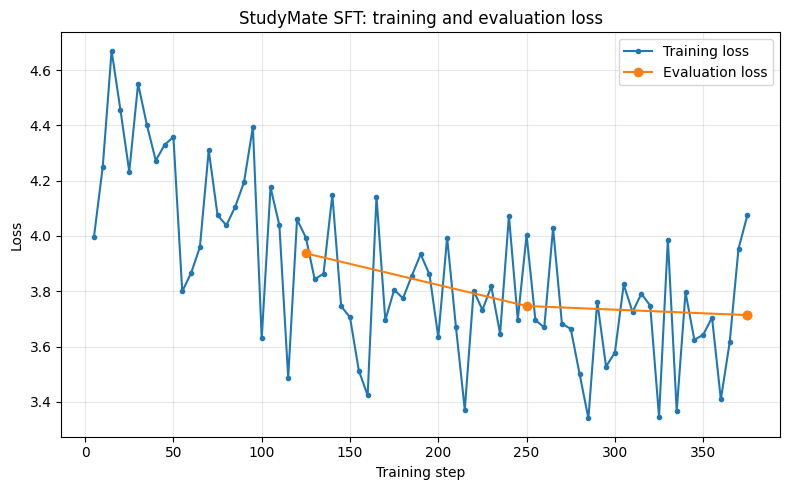

Saved: /content/drive/MyDrive/ctp/studymate-sft-results/loss_curves.png


In [18]:
history = pd.DataFrame(trainer.state.log_history)
history.to_csv(RESULTS_DIR / "training_log_history.csv", index=False)

plt.figure(figsize=(8, 5))
if "loss" in history.columns:
    train_rows = history[history["loss"].notna()]
    if len(train_rows):
        x = train_rows["step"] if "step" in train_rows else np.arange(len(train_rows))
        plt.plot(x, train_rows["loss"], marker=".", label="Training loss")

if "eval_loss" in history.columns:
    eval_rows = history[history["eval_loss"].notna()]
    if len(eval_rows):
        x = eval_rows["step"] if "step" in eval_rows else np.arange(len(eval_rows))
        plt.plot(x, eval_rows["eval_loss"], marker="o", label="Evaluation loss")

plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("StudyMate SFT: training and evaluation loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curves.png", dpi=160)
plt.show()
print("Saved:", RESULTS_DIR / "loss_curves.png")

##Generate answers for held-out test questions

By default, generation-based metrics use 50 test questions to keep runtime reasonable. Set `GENERATION_LIMIT = None` in Section 3 to evaluate all 150. This section does inference only; it does not train on test answers.

In [19]:
model.eval()

if GENERATION_LIMIT is None:
    eval_rows = test_data
else:
    eval_rows = test_data[:min(GENERATION_LIMIT, len(test_data))]

def generate_answer(instruction):
    prompt = (
        "### Instruction:\n"
        + instruction.strip()
        + "\n\n### Response:\n"
    )
    inputs = tokenizer(prompt, return_tensors="pt")
    device = next(model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=160,
            do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.eos_token_id,
            use_cache=True,
        )

    new_tokens = output_ids[0, inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return answer

predictions = []
for i, row in enumerate(eval_rows, start=1):
    pred = generate_answer(row["instruction"])
    predictions.append({
        "source": row.get("source", ""),
        "page": row.get("page", ""),
        "topic": row.get("topic", ""),
        "instruction": row["instruction"],
        "reference": row["output"].strip(),
        "prediction": pred,
    })
    if i % 10 == 0 or i == len(eval_rows):
        print(f"Generated {i}/{len(eval_rows)} answers")

pred_df = pd.DataFrame(predictions)
pred_df.to_csv(RESULTS_DIR / "sft_test_predictions.csv", index=False)
print("Saved predictions:", RESULTS_DIR / "sft_test_predictions.csv")

Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Generated 10/150 answers


Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Generated 20/150 answers


Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

...

Generated 130/150 answers


Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Generated 140/150 answers


Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=160) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

Generated 150/150 answers
Saved predictions: /content/drive/MyDrive/ctp/studymate-sft-results/sft_test_predictions.csv


##Calculate simple text metrics

In [20]:
import re
from collections import Counter
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction
from nltk.translate.bleu_score import modified_precision

def words(text):
    return re.findall(r"\b\w+\b", str(text).lower())

def token_f1(reference, prediction):
    ref, pred = words(reference), words(prediction)
    if not ref or not pred:
        return 0.0
    overlap = sum((Counter(ref) & Counter(pred)).values())
    if overlap == 0:
        return 0.0
    precision = overlap / len(pred)
    recall = overlap / len(ref)
    return 2 * precision * recall / (precision + recall)

def lcs_length(a, b):
    previous = [0] * (len(b) + 1)
    for x in a:
        current = [0]
        for j, y in enumerate(b, start=1):
            if x == y:
                current.append(previous[j - 1] + 1)
            else:
                current.append(max(previous[j], current[-1]))
        previous = current
    return previous[-1]

def rouge_l(reference, prediction):
    ref, pred = words(reference), words(prediction)
    if not ref or not pred:
        return 0.0
    lcs = lcs_length(ref, pred)
    precision = lcs / len(pred)
    recall = lcs / len(ref)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

def exact_match(reference, prediction):
    clean = lambda s: " ".join(words(s))
    return float(clean(reference) == clean(prediction))

def ngram_precision(reference, prediction, n):
    # Modified n-gram precision: clipped n-gram matches / candidate n-grams.
    ref, pred = words(reference), words(prediction)
    if len(pred) < n:
        return 0.0
    ref_counts = Counter(tuple(ref[i:i+n]) for i in range(max(0, len(ref)-n+1)))
    pred_counts = Counter(tuple(pred[i:i+n]) for i in range(len(pred)-n+1))
    clipped = sum(min(count, ref_counts[gram]) for gram, count in pred_counts.items())
    return clipped / sum(pred_counts.values())

smooth = SmoothingFunction().method1

pred_df["token_f1"] = [
    token_f1(r, p) for r, p in zip(pred_df["reference"], pred_df["prediction"])
]
pred_df["rouge_l"] = [
    rouge_l(r, p) for r, p in zip(pred_df["reference"], pred_df["prediction"])
]
pred_df["exact_match"] = [
    exact_match(r, p) for r, p in zip(pred_df["reference"], pred_df["prediction"])
]
pred_df["unigram_precision"] = [
    ngram_precision(r, p, 1) for r, p in zip(pred_df["reference"], pred_df["prediction"])
]
pred_df["bigram_precision"] = [
    ngram_precision(r, p, 2) for r, p in zip(pred_df["reference"], pred_df["prediction"])
]
pred_df["trigram_precision"] = [
    ngram_precision(r, p, 3) for r, p in zip(pred_df["reference"], pred_df["prediction"])
]
pred_df["reference_words"] = pred_df["reference"].map(lambda s: len(words(s)))
pred_df["prediction_words"] = pred_df["prediction"].map(lambda s: len(words(s)))

references = [[words(r)] for r in pred_df["reference"]]
hypotheses = [words(p) for p in pred_df["prediction"]]

bleu_scores = {}
for n in range(1, 5):
    weights = tuple([1 / n] * n + [0] * (4 - n))
    bleu_scores[f"bleu_{n}"] = corpus_bleu(
        references,
        hypotheses,
        weights=weights,
        smoothing_function=smooth,
    )

metric_summary = pd.DataFrame([{
    "questions_evaluated": len(pred_df),
    "BLEU-1": bleu_scores["bleu_1"],
    "BLEU-2": bleu_scores["bleu_2"],
    "BLEU-3": bleu_scores["bleu_3"],
    "BLEU-4": bleu_scores["bleu_4"],
    "mean_unigram_precision": pred_df["unigram_precision"].mean(),
    "mean_bigram_precision": pred_df["bigram_precision"].mean(),
    "mean_trigram_precision": pred_df["trigram_precision"].mean(),
    "mean_token_f1": pred_df["token_f1"].mean(),
    "mean_rouge_l": pred_df["rouge_l"].mean(),
    "exact_match_rate": pred_df["exact_match"].mean(),
    "mean_reference_words": pred_df["reference_words"].mean(),
    "mean_prediction_words": pred_df["prediction_words"].mean(),
    "eval_loss": eval_loss,
    "eval_perplexity": eval_perplexity,
}])

metric_summary.to_csv(RESULTS_DIR / "sft_generation_metrics.csv", index=False)
pred_df.to_csv(RESULTS_DIR / "sft_test_predictions.csv", index=False)
display(metric_summary.round(4))
print("Saved generation metrics and per-question metrics to:", RESULTS_DIR)

,questions_evaluated,BLEU-1,BLEU-2,BLEU-3,BLEU-4,mean_unigram_precision,mean_bigram_precision,mean_trigram_precision,mean_token_f1,mean_rouge_l,exact_match_rate,mean_reference_words,mean_prediction_words,eval_loss,eval_perplexity
0,150,0.1344,0.0944,0.0738,0.0599,0.2657,0.1802,0.1431,0.1852,0.1777,0.0,47.9533,71.78,3.7138,41.0083


Saved generation metrics and per-question metrics to: /content/drive/MyDrive/ctp/studymate-sft-results


##Plot text-metric scores

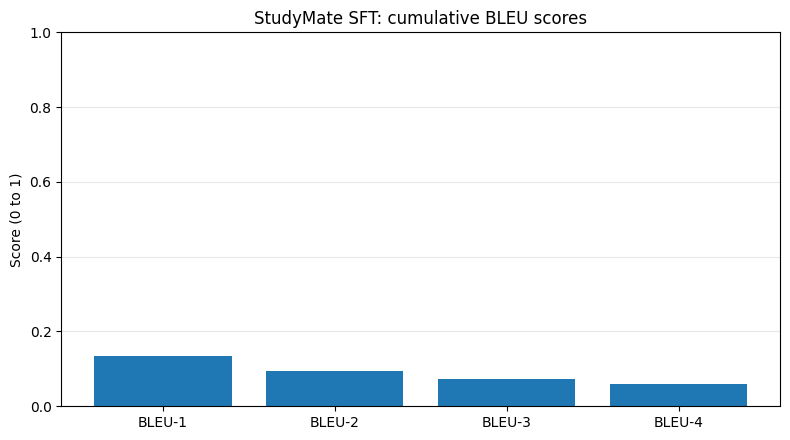

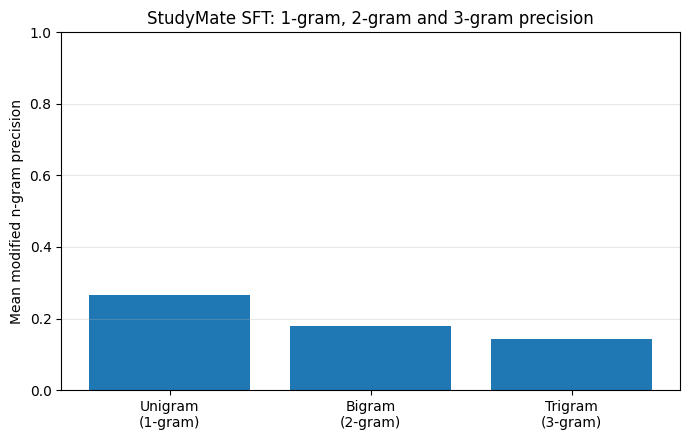

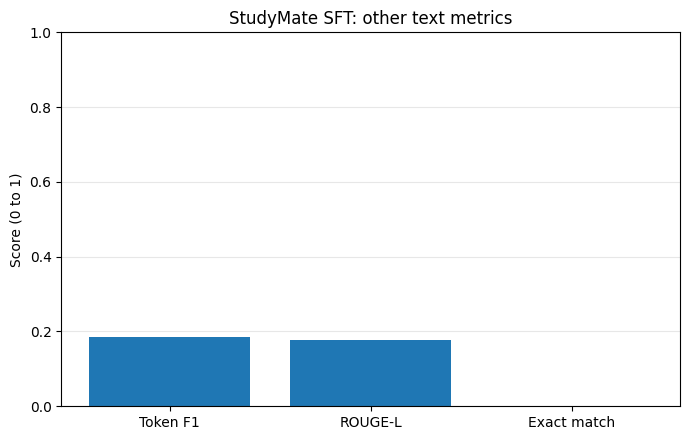

Saved BLEU, n-gram, and other metric graphs in: /content/drive/MyDrive/ctp/studymate-sft-results


In [21]:
plot_metrics = {
    "BLEU-1": metric_summary.loc[0, "BLEU-1"],
    "BLEU-2": metric_summary.loc[0, "BLEU-2"],
    "BLEU-3": metric_summary.loc[0, "BLEU-3"],
    "BLEU-4": metric_summary.loc[0, "BLEU-4"],
}

plt.figure(figsize=(8, 4.5))
plt.bar(list(plot_metrics.keys()), list(plot_metrics.values()))
plt.ylim(0, 1)
plt.ylabel("Score (0 to 1)")
plt.title("StudyMate SFT: cumulative BLEU scores")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "bleu_scores.png", dpi=160)
plt.show()

ngram_metrics = {
    "Unigram\n(1-gram)": pred_df["unigram_precision"].mean(),
    "Bigram\n(2-gram)": pred_df["bigram_precision"].mean(),
    "Trigram\n(3-gram)": pred_df["trigram_precision"].mean(),
}

plt.figure(figsize=(7, 4.5))
plt.bar(list(ngram_metrics.keys()), list(ngram_metrics.values()))
plt.ylim(0, 1)
plt.ylabel("Mean modified n-gram precision")
plt.title("StudyMate SFT: 1-gram, 2-gram and 3-gram precision")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "ngram_precision.png", dpi=160)
plt.show()

other_metrics = {
    "Token F1": metric_summary.loc[0, "mean_token_f1"],
    "ROUGE-L": metric_summary.loc[0, "mean_rouge_l"],
    "Exact match": metric_summary.loc[0, "exact_match_rate"],
}
plt.figure(figsize=(7, 4.5))
plt.bar(list(other_metrics.keys()), list(other_metrics.values()))
plt.ylim(0, 1)
plt.ylabel("Score (0 to 1)")
plt.title("StudyMate SFT: other text metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "text_metrics.png", dpi=160)
plt.show()

print("Saved BLEU, n-gram, and other metric graphs in:", RESULTS_DIR)

## 17. Plot the score distributions

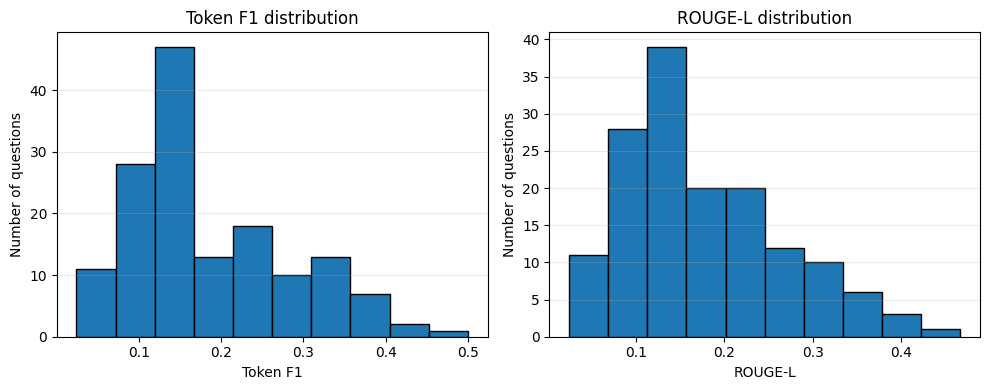

Saved: /content/drive/MyDrive/ctp/studymate-sft-results/metric_distributions.png


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(pred_df["token_f1"], bins=10, edgecolor="black")
axes[0].set_title("Token F1 distribution")
axes[0].set_xlabel("Token F1")
axes[0].set_ylabel("Number of questions")

axes[1].hist(pred_df["rouge_l"], bins=10, edgecolor="black")
axes[1].set_title("ROUGE-L distribution")
axes[1].set_xlabel("ROUGE-L")
axes[1].set_ylabel("Number of questions")

for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "metric_distributions.png", dpi=160)
plt.show()
print("Saved:", RESULTS_DIR / "metric_distributions.png")

##Compare reference and generated answer lengths

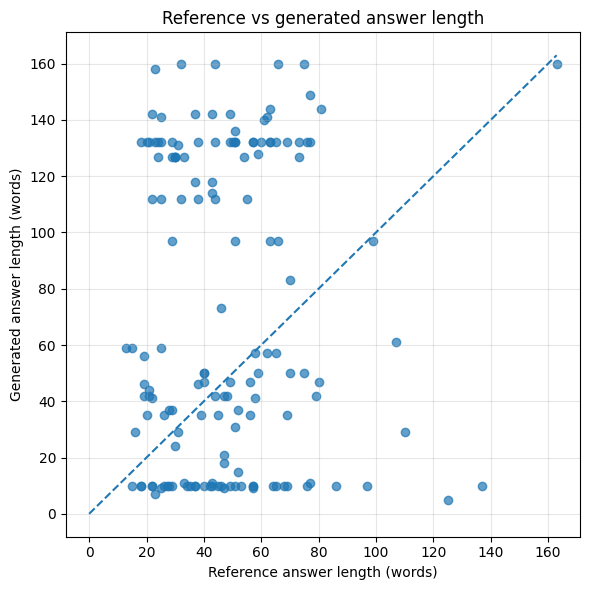

Saved: /content/drive/MyDrive/ctp/studymate-sft-results/answer_length_comparison.png


In [23]:
plt.figure(figsize=(6, 6))
plt.scatter(
    pred_df["reference_words"],
    pred_df["prediction_words"],
    alpha=0.7
)
max_words = max(
    pred_df["reference_words"].max(),
    pred_df["prediction_words"].max(),
    1
)
plt.plot([0, max_words], [0, max_words], linestyle="--")
plt.xlabel("Reference answer length (words)")
plt.ylabel("Generated answer length (words)")
plt.title("Reference vs generated answer length")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "answer_length_comparison.png", dpi=160)
plt.show()
print("Saved:", RESULTS_DIR / "answer_length_comparison.png")

##Review example predictions

In [24]:
pd.set_option("display.max_colwidth", 180)
display(
    pred_df[["instruction", "reference", "prediction", "token_f1", "rouge_l"]]
    .head(10)
)

,instruction,reference,prediction,token_f1,rouge_l
0,"Explain the main points presented about of a good stone Durability (source: 1.pdf, page 23).",of a good stone Durability It the period in for which a stone may stand being used in construction Water absorption Moisture the strength of the and as such that contain or abs...,"of a good stone Durability (source: 1.pdf, page 23)",0.093458,0.093458
1,"What facts, properties, categories, or steps does the slide state about construction materials and material selection (source: 1.pdf, page 23)?",Key points stated on the slide:\n- Durability It the period in for which a stone may stand being used in construction\n- Water absorption Moisture the strength of the and as su...,Key points stated on the slide:\n- Construction materials\n- Material selection\n- Selection of materials\n- Selection of materials\n- Selection of materials\n- Selection of ma...,0.142857,0.142857
2,"Explain the main points presented about 2S A 0 English ott (source: 8.pdf, page 18).",2S A 0 English ott 1 great errata A queen must be provided a quoin header or first header A header course should never start with a queen Each alternate header should be placed...,"2S A 0 English ott (source: 8.pdf, page 18)",0.068027,0.068027
3,"What facts, properties, categories, or steps does the slide state about stone and brick masonry (source: 8.pdf, page 18)?",Key points stated on the slide:\n- 2S A 0 English ott 1 great errata\n- A queen must be provided a quoin header or first header A header course should never start with a queen\...,Key points stated on the slide:\n- The most common type of masonry is stone and brick masonry\n- The most common type of masonry is stone and brick masonry\n- The most common t...,0.176000,0.176000
4,"Explain the main points presented about from a roof Strength and (source: 10.pdf, page 43).",from a roof Strength and stability The roof structure should be strong and stable enough to take up the anticipated Weather resistance The roof should have adequate resistance ...,From a roof Strength and,0.076923,0.076923
5,"What facts, properties, categories, or steps does the slide state about building classification and construction types (source: 10.pdf, page 43)?",The slide highlights: from a roof Strength and stability The roof structure should be strong and stable enough to take up the anticipated Weather resistance The roof should hav...,Key points stated on the slide:\n- The building classification is based on the building type\n- The building classification is based on the building type\n- The building classi...,0.089552,0.089552
6,"Explain the main points presented about Bearing Capacity Ultimate bearing capacity (source: 7.pdf, page 8).",Bearing Capacity Ultimate bearing capacity or Gross bearing capacity It is the least gross pressure which will cause shear failure of the soil below the footing Net ultimate be...,Bearing Capacity Ultimate bearing capacity of a soil is the maximum load that a soil can withstand before it breaks or fails. It is also known as ultimate bearing capacity or u...,0.318584,0.274336
7,"What facts, properties, categories, or steps does the slide state about foundations and bearing capacity (source: 7.pdf, page 8)?",Key points stated on the slide:\n- Ultimate bearing capacity or Gross bearing capacity It is the least gross pressure which will cause shear failure of the soil below the footi...,Key points stated on the slide:\n- The foundation is the base of the structure\n- The bearing capacity is the ability of the soil to resist the pressure of the soil above the f...,0.328889,0.328889
8,"Explain the main points presented about of a good stone Crushing (source: 1.pdf, page 22).",of a good stone Crushing strength Should have sufficient strength to withstand Hardness Should be hard for flooring and pavement Appearance Important from an architectural poin...,"of a good stone Crushing (source: 1.pdf, page 22)",0.135135,0.135135
9,"What facts, properties, categories, or s

##Save a final summary report

In [25]:
report = {
    "base_dapt_adapter": DAPT_MODEL_ID,
    "train_examples": len(train_data),
    "test_examples": len(test_data),
    "generation_examples_evaluated": len(pred_df),
    "epochs_configured": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "max_seq_length": MAX_SEQ_LENGTH,
    "eval_loss": float(eval_loss) if eval_loss is not None else None,
    "eval_perplexity": float(eval_perplexity) if np.isfinite(eval_perplexity) else None,
    "bleu_1": float(metric_summary.loc[0, "BLEU-1"]),
    "bleu_2": float(metric_summary.loc[0, "BLEU-2"]),
    "bleu_3": float(metric_summary.loc[0, "BLEU-3"]),
    "bleu_4": float(metric_summary.loc[0, "BLEU-4"]),
    "mean_unigram_precision": float(pred_df["unigram_precision"].mean()),
    "mean_bigram_precision": float(pred_df["bigram_precision"].mean()),
    "mean_trigram_precision": float(pred_df["trigram_precision"].mean()),
    "mean_token_f1": float(pred_df["token_f1"].mean()),
    "mean_rouge_l": float(pred_df["rouge_l"].mean()),
    "exact_match_rate": float(pred_df["exact_match"].mean()),
    "outputs_directory": str(SFT_OUTPUT_DIR),
    "results_directory": str(RESULTS_DIR),
    "note": (
        "Dataset is OCR-derived and may contain artifacts. Text-overlap metrics "
        "do not establish factual correctness. Test examples are held out from SFT, "
        "but their source PDFs were also used for DAPT."
    ),
}
with (RESULTS_DIR / "sft_evaluation_report.json").open("w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print("\nAll evaluation files saved in:", RESULTS_DIR)

{
  "base_dapt_adapter": "ksumanthreddy96/studymate-ctp-dapt",
  "train_examples": 500,
  "test_examples": 150,
  "generation_examples_evaluated": 150,
  "epochs_configured": 3,
  "learning_rate": 1e-05,
  "max_seq_length": 256,
  "eval_loss": 3.7137744426727295,
  "eval_perplexity": 41.0082982543606,
  "bleu_1": 0.1343921240828457,
  "bleu_2": 0.0944000729533677,
  "bleu_3": 0.0737940724207866,
  "bleu_4": 0.05987647650659499,
  "mean_unigram_precision": 0.2656900375724338,
  "mean_bigram_precision": 0.18024543345881738,
  "mean_trigram_precision": 0.14310506173205303,
  "mean_token_f1": 0.18521570493283432,
  "mean_rouge_l": 0.177747115626588,
  "exact_match_rate": 0.0,
  "outputs_directory": "/content/drive/MyDrive/ctp/studymate-sft",
  "results_directory": "/content/drive/MyDrive/ctp/studymate-sft-results",
  "note": "Dataset is OCR-derived and may contain artifacts. Text-overlap metrics do not establish factual correctness. Test examples are held out from SFT, but their source PDF

## What to check after running

Files saved in `ctp/studymate-sft-results`:
- `training_log_history.csv`
- `sft_loss_evaluation.csv`
- `loss_curves.png`
- `sft_test_predictions.csv`
- `sft_generation_metrics.csv`
- `bleu_scores.png`
- `ngram_precision.png`
- `text_metrics.png`
- `metric_distributions.png`
- `answer_length_comparison.png`
- `sft_evaluation_report.json`

**Metric note:** token F1 and ROUGE-L measure text overlap, not factual correctness. Inspect the prediction CSV and correct any OCR-derived reference errors before drawing strong conclusions. The held-out set is separate from SFT training, but it is not fully independent of DAPT because the same lecture PDFs were used in DAPT.